# Support Ticket AI - Analysis Walkthrough
**Author:** Sazia Parween · Data Analyst

**Business problem:** A support team receives ~1,500 tickets a month. Tickets are routed by hand, angry customers are spotted late, and ~1 in 4 tickets escalates to a manager. Each escalation costs senior-agent time and hurts CSAT.

**Goal:** use the ticket text + basic metadata to
1. auto-route tickets to the right team (category classification),
2. flag negative / angry customers (sentiment),
3. predict which tickets will escalate so team leads can step in early.

This notebook walks through the pipeline. The production code lives in `src/`.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
pd.set_option('display.max_colwidth', 90)
raw = pd.read_csv('../data/raw/tickets_raw.csv')
print(raw.shape)
raw.sample(5, random_state=1)[['ticket_id','created_at','channel','category','ticket_text']]

(9120, 15)


,ticket_id,created_at,channel,category,ticket_text
1975,TCK-102301,10-Jan-2026 06:30 PM,Chat,DELIVERY,delivery address needs to be hcanged for #OD413086569. love your app otherwise :)
82,TCK-107001,2026-04-25 18:21:00,Chat,Refund,refund amount is less than what I paid. also need to delete my account permanently. th...
4537,TCK-103552,2026-01-19 07:10:00,Phone,Refund,refund maount is less than wha I paid. very bad experience.
6277,TCK-104283,27/06/2026 14:00,Phone,Account Access,NEED TO DELETE MY ACCOUNT PERMANENTLY. WORST SERVICE EVER!!
6523,TCK-107334,27-Mar-2026 02:06 AM,Chat,Account Access,ACCOUNT LOCKED AFTER TOO MANY ATTEMPTS.


## 1. Data quality check
The raw CRM export has the usual problems: duplicates, mixed date formats, inconsistent labels (`billing`, ` Billing `, `Technical_Issue`), junk text and impossible response times.

In [2]:
print('Duplicate rows:', raw.duplicated().sum())
print('Category spellings:', raw['category'].nunique(), '(should be 6)')
print('Channel spellings :', raw['channel'].nunique(), '(should be 5)')
print('Bad response times:', ((raw.first_response_min <= 0) | (raw.first_response_min > 10080)).sum())
raw.isna().sum()[lambda s: s > 0]

Duplicate rows: 120
Category spellings: 27 (should be 6)
Channel spellings : 17 (should be 5)
Bad response times: 25


resolved_at           1443
customer_tier          184
city                   365
ticket_text              5
first_response_min     274
csat_score            4932
dtype: int64

In [3]:
import clean
df = clean.main()   # runs every cleaning step and writes the data-quality report
df.head(3)

Raw rows                                                      9,120
Exact duplicate rows removed                                    120
Duplicate ticket_id rows removed                                  0
Rows with empty/junk ticket text removed                         30
Category labels standardised (case/spaces/underscores)          559
Channel labels standardised                                     343
Unparseable created_at dates                                      0
Invalid first_response_min values (<=0 or >7 days) set to null     25
first_response_min imputed with channel median                  293
Missing city filled with 'Unknown'                              357
Missing customer_tier filled with 'Unknown'                     179
Clean rows                                                    8,970


,ticket_id,created_at,resolved_at,channel,customer_tier,city,agent_id,ticket_text,category,sentiment,...,escalated,csat_score,resolution_hours,created_date,created_month,created_hour,weekday,text_clean,exclamations,caps_ratio
0,TCK-108225,2026-06-27 19:25:00,2026-06-28 02:29:44,Chat,Gold,Delhi,AGT116,"abe to login, OTP not coming. htis si the 3dr time I am complaining, NOBODY helps",Technical Issue,Angry,...,0,4.0,7.078889,2026-06-27,2026-06,19,Saturday,abe to login otp not coming htis si the dr time i am complaining nobody helps,0,0.161
1,TCK-103133,2026-04-06 09:46:00,2026-04-06 23:23:14,Chat,Silver,Jaipur,AGT138,"UNABLE TO LOGIN, OTP NOT COMNG. WORST SERVIEC EVER!!",Technical Issue,Angry,...,1,2.0,13.620556,2026-04-06,2026-04,9,Monday,unable to login otp not comng worst serviec ever!!,2,1.000
2,TCK-101446,2026-03-26 13:08:00,NaT,Chat,Silver,Kolkata,AGT124,I returned the poduct but refund not received. thanks. please jaldi solev kar,Refund,Neutral,...,0,NaN,NaN,2026-03-26,2026-03,13,Thursday,i returned the poduct but refund not received thanks please jaldi solev kar,0,0.016


## 2. SQL KPI analysis
The clean data is loaded into SQLite and analysed with SQL (`sql/kpi_queries.sql`): aggregations, CASE buckets, subqueries, CTEs and window functions.

In [4]:
import sqlite3
from sql_analysis import load_queries, SQL_FILE, DB
queries = dict(load_queries(SQL_FILE))
con = sqlite3.connect(DB)
for name in ['2. Category performance (volume, escalation, resolution time, CSAT)',
             '4. Repeat contacts drive escalations']:
    print(name)
    display(pd.read_sql_query(queries[name], con))

2. Category performance (volume, escalation, resolution time, CSAT)


,category,tickets,share_pct,escalation_rate_pct,avg_resolution_hrs,avg_csat
0,Technical Issue,1938,21.6,19.3,12.2,3.67
1,Billing,1808,20.2,29.5,23.2,3.31
2,Delivery,1765,19.7,28.2,37.0,3.15
3,Refund,1500,16.7,30.0,56.8,3.01
4,Account Access,1213,13.5,25.2,11.0,3.56
5,Product Inquiry,746,8.3,9.9,5.0,3.84


4. Repeat contacts drive escalations


,previous_contacts_bucket,tickets,escalation_rate_pct
0,0 (first contact),3252,10.1
1,1,2942,21.7
2,2,1642,37.3
3,3+,1134,57.8


**Insight:** escalation rate rises from ~10% on first contact to almost 58% for customers contacting a 3rd+ time. Fixing issues on the *first* contact is the biggest lever.

## 3. Exploratory analysis

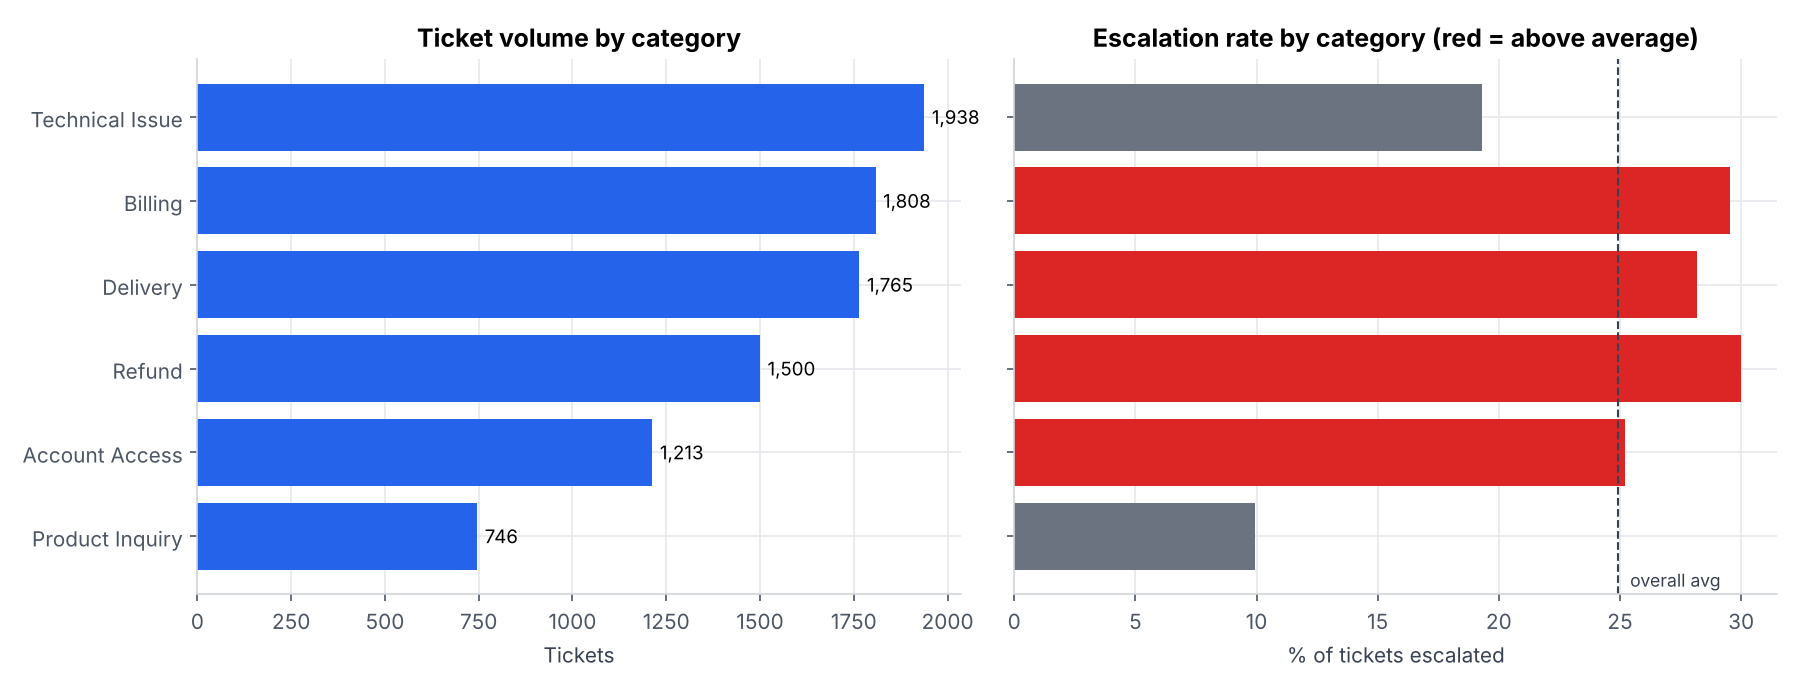

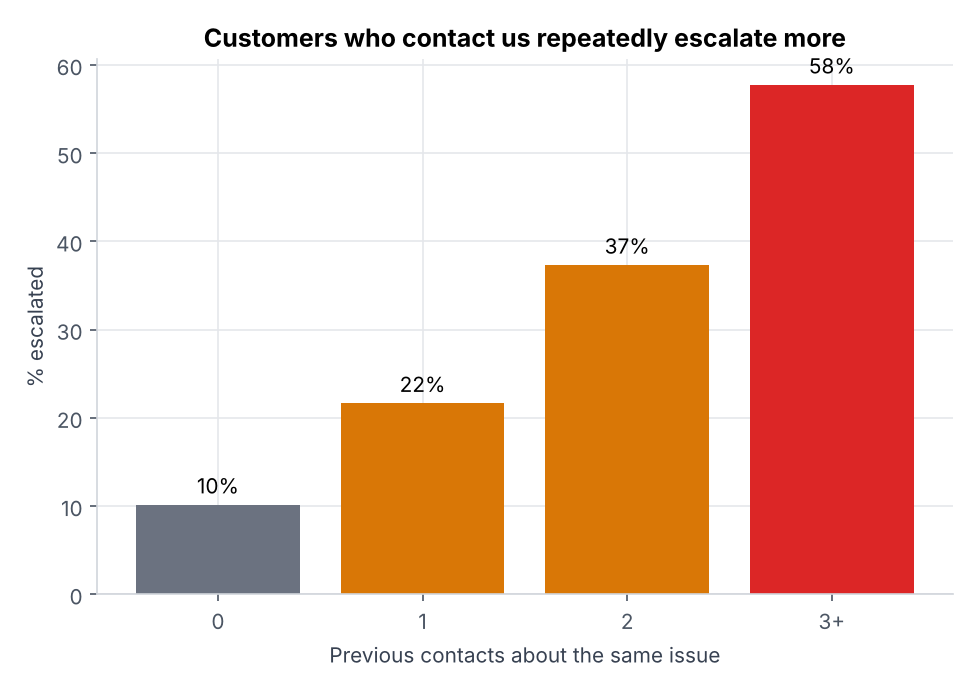

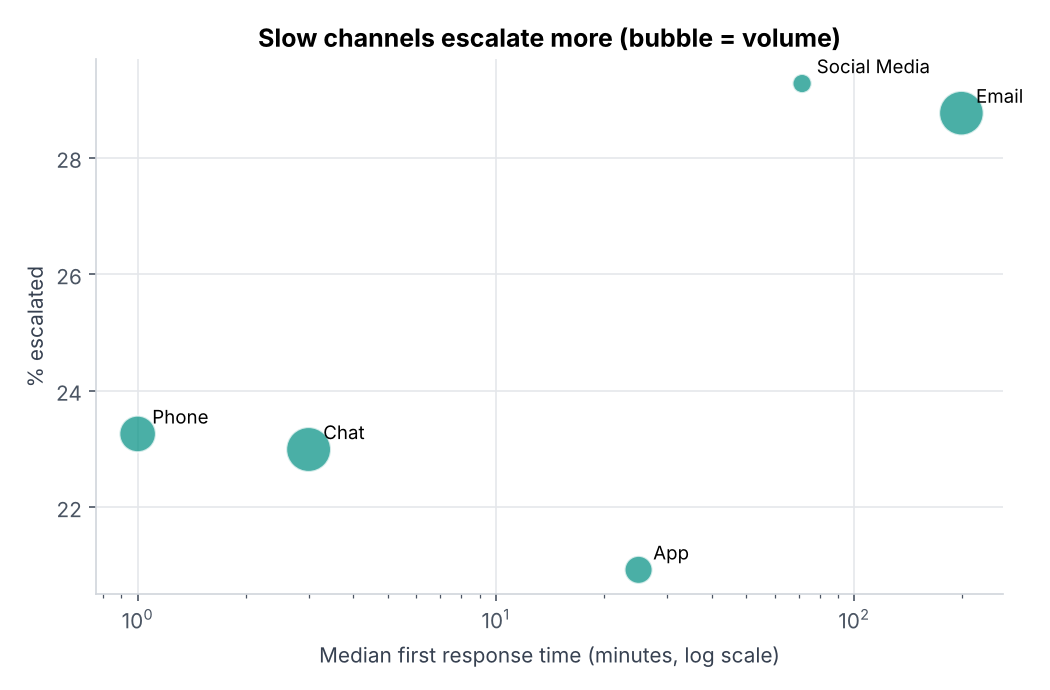

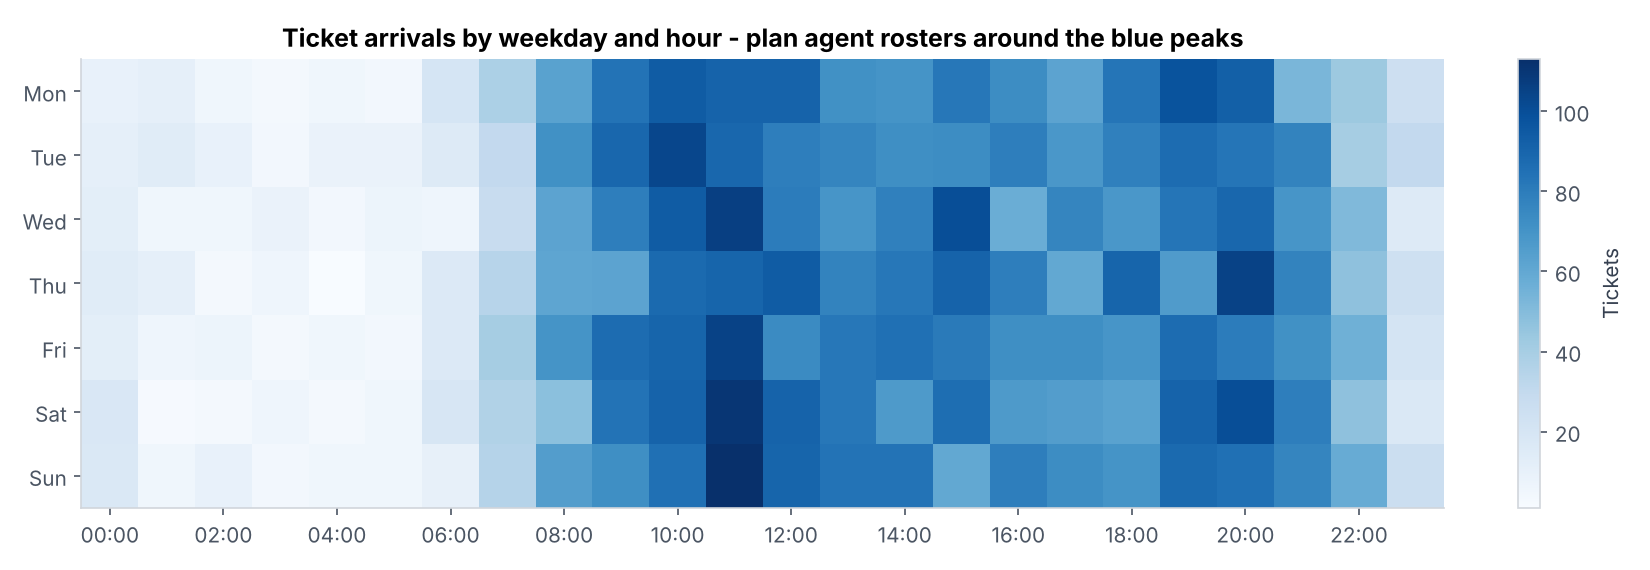

In [5]:
from IPython.display import Image, display
for f in ['eda_category', 'eda_repeat_contacts', 'eda_channels', 'eda_heatmap']:
    display(Image(f'../reports/figures/{f}.png', width=820))

## 4. AI models
Validation uses a **time-based split**: train on Jan–May, test on June. This is how the model would be used for real (learn from the past, score new tickets), and it avoids an over-optimistic random split.

In [6]:
m = json.load(open('../reports/metrics.json'))
pd.DataFrame(m['category']['model_comparison']).T

,accuracy,macro_f1
Naive Bayes,0.8891,0.8801
Logistic Regression,0.9163,0.9100
Linear SVM,0.9243,0.9175


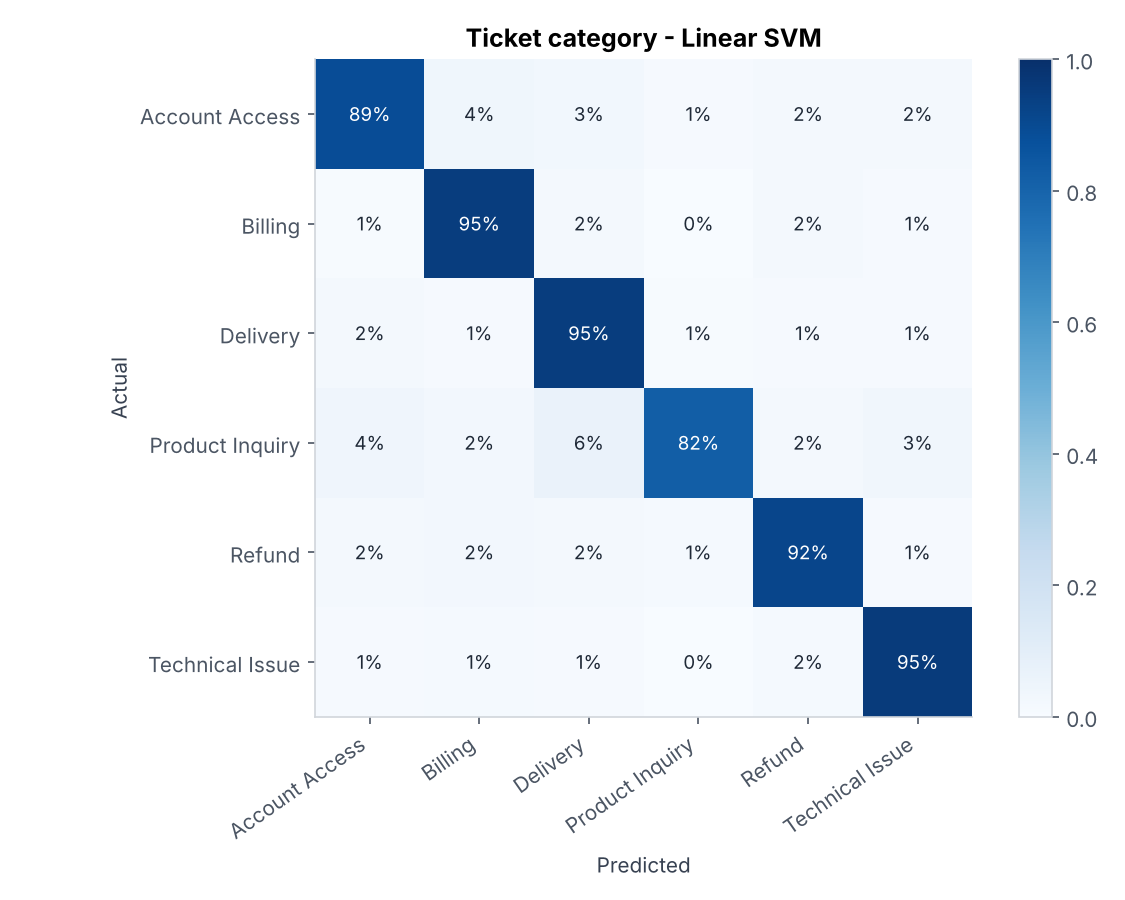

In [7]:
display(Image('../reports/figures/category_confusion_matrix.png', width=560))

In [8]:
pd.DataFrame(m['escalation']['comparison']).T

,roc_auc,pr_auc,capture_top20pct
Baseline (metadata only),0.7605,0.5202,0.4427
AI model (text + metadata),0.7811,0.5324,0.4533


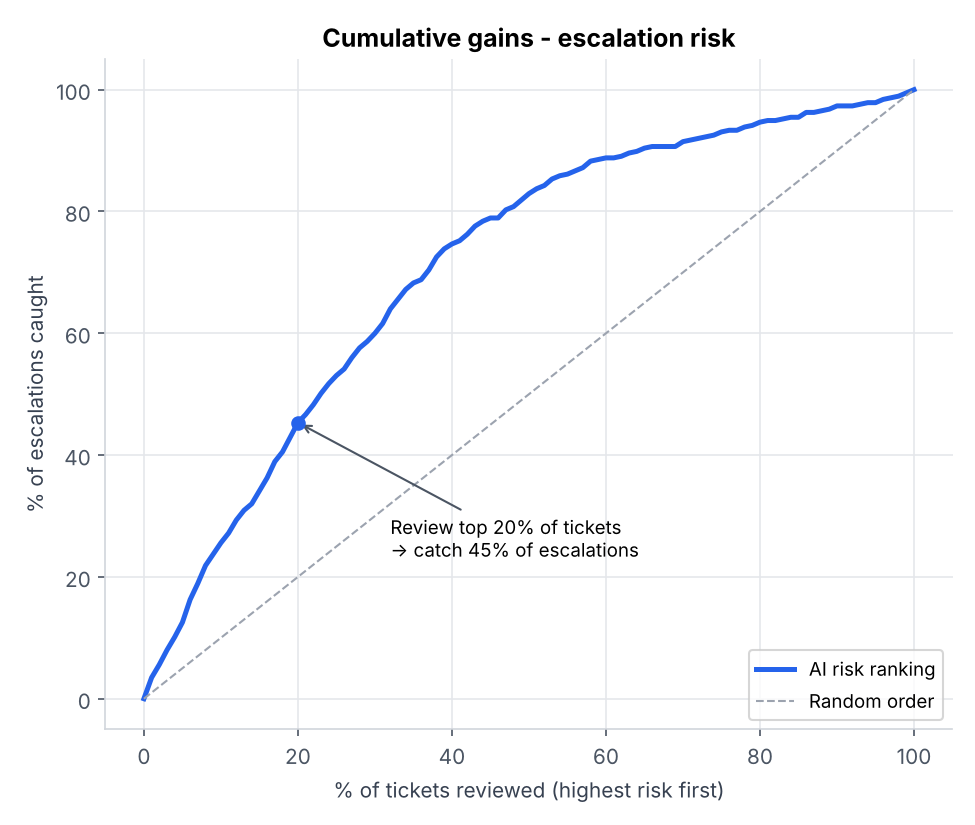

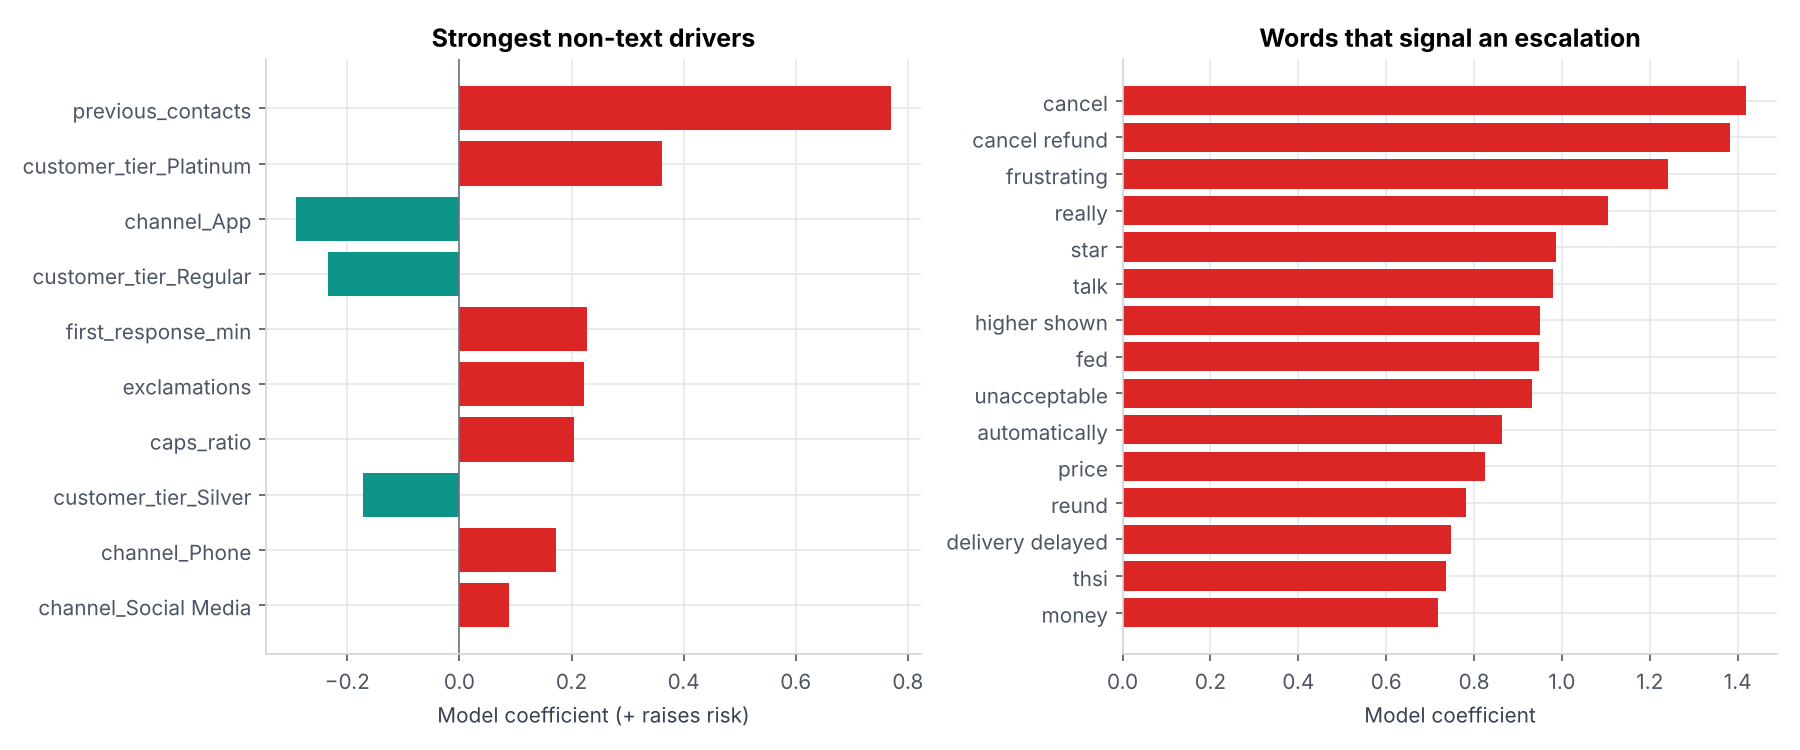

In [9]:
display(Image('../reports/figures/escalation_gains.png', width=520))
display(Image('../reports/figures/escalation_drivers.png', width=900))

## 5. Try it on a new ticket

In [10]:
from predict import analyze_ticket
analyze_ticket('I was charged twice and NOBODY is replying!! 3rd time I am complaining',
               channel='Email', customer_tier='Gold', previous_contacts=3, first_response_min=300)

{'category': 'Billing',
 'route_to': 'Payments & Billing team',
 'sentiment': 'Angry',
 'sentiment_probabilities': {'Angry': 0.943,
  'Negative': 0.057,
  'Neutral': 0.0,
  'Positive': 0.0},
 'escalation_risk': 0.909,
 'risk_level': 'HIGH',
 'recommended_action': 'Assign a senior agent now and call the customer back within 1 hour.'}

## 6. Recommendations
1. **Auto-route** with the category model (92% accuracy) — removes manual triage for most tickets; low-confidence tickets still go to a human.
2. **Risk queue:** review the top 20% riskiest tickets each day — this catches ~45% of all escalations, more than twice what random review would.
3. **First-contact resolution:** repeat contacts are the #1 escalation driver — add a callback rule for any customer's 2nd contact.
4. **Email SLA:** email has the slowest first response and an above-average escalation rate — move refund/billing emails to chat or set a 2-hour SLA.
5. **Roster for peaks:** staff up 10:00–12:00 and 19:00–21:00 when volume peaks.

*Limitations:* the dataset is simulated (real tickets contain customer PII), so exact numbers will differ on real data; the pipeline and method transfer directly.